In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

In [18]:
def one_hot(y, num_classes=10):

    onehot = np.zeros((len(y), num_classes))
    onehot[np.arange(len(y)), y] = 1
    return onehot

In [19]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()
y_train = one_hot(y_train)
y_test = one_hot(y_test)
print(X_train.shape,X_train.dtype)
print(y_train.shape,y_train.dtype)
print(X_train.min(),X_train.max())

(60000, 28, 28) uint8
(60000, 10) float64
0 255


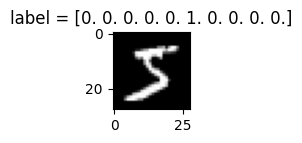

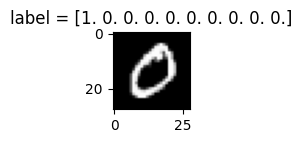

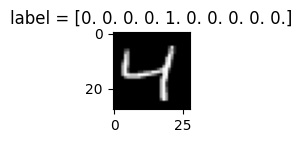

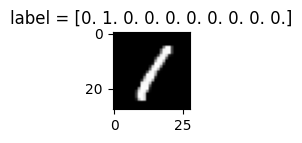

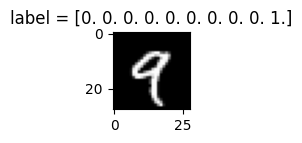

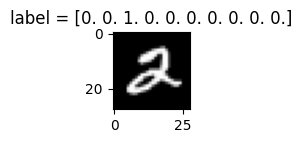

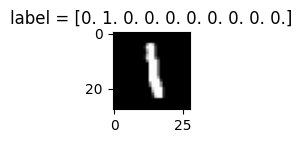

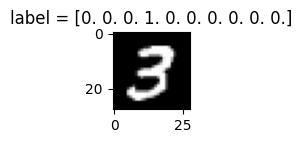

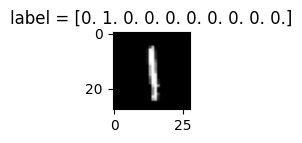

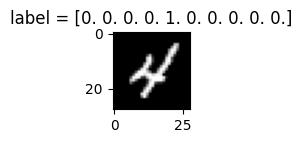

In [20]:
#VISUALISATION

for i in range(10):
  plt.figure(figsize=(1,1))
  plt.imshow(X_train[i],cmap='gray')
  plt.title(f"label = {y_train[i]}")
  plt.show()


In [21]:
#NORMALIZING
X_train=X_train/255.0
X_test=X_test/255.0

#FLATTENING (28*28=784)
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)
print(X_train.shape)
print(X_test.shape)


(60000, 784)
(10000, 784)


In [22]:
#ACTIVATION FUNCTIONS
def relu(Z):
    return np.maximum(0, Z)

def relu_derivative(Z):
    return (Z > 0).astype(int)

def softmax(Z):
    exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)


In [23]:
def forward_propogation(X,W1,b1,W2,b2,W3,b3):

  Z1= X@W1+b1
  A1=relu(Z1)

  Z2= A1@W2+b2
  A2=relu(Z2)

  Z3= A2@W3+b3
  A3=softmax(Z3)

  cache=(X,Z1,A1,b1,Z2,A2,b2,Z3,A3,b3)
  return A3,cache


In [24]:
def compute_loss(y,y_pred):
  m=y.shape[0]
  loss = -np.sum(y*np.log(y_pred+1e-10))/m
  return loss

In [25]:
def backward_propogation(W1,W2,W3,cache,y):

  m=y.shape[0]
  X,Z1,A1,b1,Z2,A2,b2,Z3,A3,b3=cache

  dZ3=A3-y
  dW3=A2.T@dZ3/m
  db3=np.sum(dZ3,axis=0,keepdims=True)/m

  dA2=dZ3@W3.T
  dZ2=dA2*relu_derivative(Z2)
  dW2=A1.T@dZ2/m
  db2=np.sum(dZ2,axis=0,keepdims=True)/m

  dA1=dZ2@W2.T
  dZ1=dA1*relu_derivative(Z1)
  dW1=X.T@dZ1/m
  db1=np.sum(dZ1,axis=0,keepdims=True)/m

  return dW1,db1,dW2,db2,dW3,db3


In [26]:
def update_parameters(W1,b1,W2,b2,W3,b3,dW1,db1,dW2,db2,dW3,db3,lr):
  W1=W1-lr*dW1
  b1=b1-lr*db1
  W2=W2-lr*dW2
  b2=b2-lr*db2
  W3=W3-lr*dW3
  b3=b3-lr*db3

  return W1,b1,W2,b2,W3,b3

In [27]:
def predict(X,W1,b1,W2,b2,W3,b3):
  y_pred,cache=forward_propogation(X,W1,b1,W2,b2,W3,b3)
  return np.argmax(y_pred,axis=1)

In [28]:
def accuracy(X_test,y_test,W1,b1,W2,b2,W3,b3):
    prediction = predict(X_test,W1,b1,W2,b2,W3,b3)
    truth = np.argmax(y_test,axis=1)
    return np.mean(prediction == truth)

In [29]:
def train(X_train,y_train,epochs,learning_rate):
   W1=np.random.randn(784,128) * np.sqrt(2/784)
   b1=np.zeros((1,128))
   W2=np.random.randn(128,64) * np.sqrt(2/128)
   b2=np.zeros((1,64))
   W3=np.random.randn(64,10) * np.sqrt(2/64)
   b3=np.zeros((1,10))

   for i in range(epochs):
    output,cache=forward_propogation(X_train,W1,b1,W2,b2,W3,b3)
    loss=compute_loss(y_train,output)
    dW1,db1,dW2,db2,dW3,db3=backward_propogation(W1,W2,W3,cache,y_train)
    W1,b1,W2,b2,W3,b3=update_parameters(W1,b1,W2,b2,W3,b3,dW1,db1,dW2,db2,dW3,db3,learning_rate)

    if i%10==0:
      print(f"Epoch {i} loss = {loss:.4f}")
   return W1,b1,W2,b2,W3,b3

In [33]:
#Training the model and checking accuracy
W1,b1,W2,b2,W3,b3=train(X_train,y_train,epochs=100,learning_rate=0.2)
acc=accuracy(X_test,y_test,W1,b1,W2,b2,W3,b3)
print(f"Accuracy = {acc*100:.2f}%")

Epoch 0 loss = 2.4255
Epoch 10 loss = 1.1054
Epoch 20 loss = 0.7466
Epoch 30 loss = 0.5537
Epoch 40 loss = 0.5182
Epoch 50 loss = 0.4310
Epoch 60 loss = 0.3704
Epoch 70 loss = 0.3507
Epoch 80 loss = 0.3600
Epoch 90 loss = 0.3333
Accuracy = 91.82%
